# Problem 3: Unigram Frequency Analysis of Wikipedia Articles

- Dataset: WikiText-2

- Write a Python program to analyze Wikipedia text and construct a unigram frequency model.

- Tasks: Read the training dataset, convert text into lowercase, tokenize the text, calculate the frequency of every word, identify the 20 most frequent words and calculate the unigram probability of any five selected words.

- Expected output: Word-frequency table, unigram probabilities and a bar chart of the 20 most frequent words.

In [1]:
!pip install -q datasets pandas matplotlib

# Dataset: WikiText-2

import re
from collections import Counter

import pandas as pd
import matplotlib.pyplot as plt
from datasets import load_dataset

In [2]:
# --------------------------------------------------
# STEP 1: LOAD THE TRAINING DATASET
# --------------------------------------------------

dataset = load_dataset(
    "Salesforce/wikitext",
    "wikitext-2-raw-v1"
)

train_data = dataset["train"]

print("Dataset loaded successfully")
print("Number of training rows:", len(train_data))

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

wikitext-2-raw-v1/test-00000-of-00001.pa(…): reconstructing file:   0%|          |  0.00B /  733kB            

wikitext-2-raw-v1/test-00000-of-00001.pa(…): downloading bytes:           |  0.00B            

wikitext-2-raw-v1/train-00000-of-00001.p(…): reconstructing file:   0%|          |  0.00B / 6.36MB            

wikitext-2-raw-v1/train-00000-of-00001.p(…): downloading bytes:           |  0.00B            

...

wikitext-2-raw-v1/validation-00000-of-00(…): downloading bytes:           |  0.00B            

Generating test split:   0%|          | 0/4358 [00:00<?, ? examples/s]

Generating train split:   0%|          | 0/36718 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/3760 [00:00<?, ? examples/s]

Dataset loaded successfully
Number of training rows: 36718


In [3]:
# --------------------------------------------------
# STEP 2: COMBINE THE TEXT
# --------------------------------------------------

text_corpus = "\n".join(
    row["text"] for row in train_data
)

print("Original corpus characters:", len(text_corpus))

Original corpus characters: 10929707


In [4]:
# --------------------------------------------------
# STEP 3: CONVERT TEXT TO LOWERCASE
# --------------------------------------------------

text_corpus = text_corpus.lower()

print("\nLowercase text sample:")
print(text_corpus[:300])


Lowercase text sample:

 = valkyria chronicles iii = 


 senjō no valkyria 3 : unrecorded chronicles ( japanese : 戦場のヴァルキュリア3 , lit . valkyria of the battlefield 3 ) , commonly referred to as valkyria chronicles iii outside japan , is a tactical role @-@ playing video game developed by sega and media.vision for the playst


In [5]:
# --------------------------------------------------
# STEP 4: TOKENIZE THE TEXT
# --------------------------------------------------

# Extract alphabetic words, contractions and numeric tokens.
# Punctuation is excluded from the unigram vocabulary.

tokens = re.findall(
    r"[^\W\d_]+(?:['’][^\W\d_]+)*|\d+(?:\.\d+)?",
    text_corpus,
    flags=re.UNICODE
)

print("\nTokenization completed")
print("Total number of tokens:", len(tokens))
print("Sample tokens:", tokens[:30])


Tokenization completed
Total number of tokens: 1757552
Sample tokens: ['valkyria', 'chronicles', 'iii', 'senjō', 'no', 'valkyria', '3', 'unrecorded', 'chronicles', 'japanese', '戦場のヴァルキュリア', '3', 'lit', 'valkyria', 'of', 'the', 'battlefield', '3', 'commonly', 'referred', 'to', 'as', 'valkyria', 'chronicles', 'iii', 'outside', 'japan', 'is', 'a', 'tactical']


In [6]:
# --------------------------------------------------
# STEP 5: CALCULATE WORD FREQUENCIES
# --------------------------------------------------

word_frequency = Counter(tokens)

total_tokens = len(tokens)
unique_words = len(word_frequency)

print("\nFREQUENCY ANALYSIS")
print("Total tokens:", total_tokens)
print("Unique words/tokens:", unique_words)


FREQUENCY ANALYSIS
Total tokens: 1757552
Unique words/tokens: 65021


In [7]:
# --------------------------------------------------
# STEP 6: IDENTIFY THE TOP 20 MOST FREQUENT WORDS
# --------------------------------------------------

top_20 = word_frequency.most_common(20)

frequency_table = pd.DataFrame(
    top_20,
    columns=["Word", "Frequency"]
)

print("\nTOP 20 MOST FREQUENT WORDS")
print(frequency_table.to_string(index=False))


TOP 20 MOST FREQUENT WORDS
Word  Frequency
 the     130771
  of      57032
 and      50738
  in      45019
  to      39522
   a      36666
 was      21008
   s      16253
  on      15143
  as      15058
that      14351
 for      13795
with      13012
  by      12718
  is      11692
  it       9278
from       9229
  at       9071
 his       9020
  he       8718


In [8]:
# --------------------------------------------------
# STEP 7: CALCULATE UNIGRAM PROBABILITIES
# --------------------------------------------------

# Change these to any five words you want to analyze.
selected_words = [
    "the",
    "of",
    "and",
    "wikipedia",
    "language"
]

probability_results = []

for word in selected_words:
    word = word.lower()
    frequency = word_frequency.get(word, 0)

    probability = (
        frequency / total_tokens
        if total_tokens > 0 else 0
    )

    probability_results.append({
        "Word": word,
        "Frequency": frequency,
        "Unigram Probability": probability
    })

probability_table = pd.DataFrame(probability_results)

print("\nUNIGRAM PROBABILITIES")
print(probability_table.to_string(
    index=False,
    formatters={
        "Unigram Probability": lambda p: f"{p:.8f}"
    }
))


UNIGRAM PROBABILITIES
     Word  Frequency Unigram Probability
      the     130771          0.07440520
       of      57032          0.03244968
      and      50738          0.02886856
wikipedia         30          0.00001707
 language        247          0.00014054


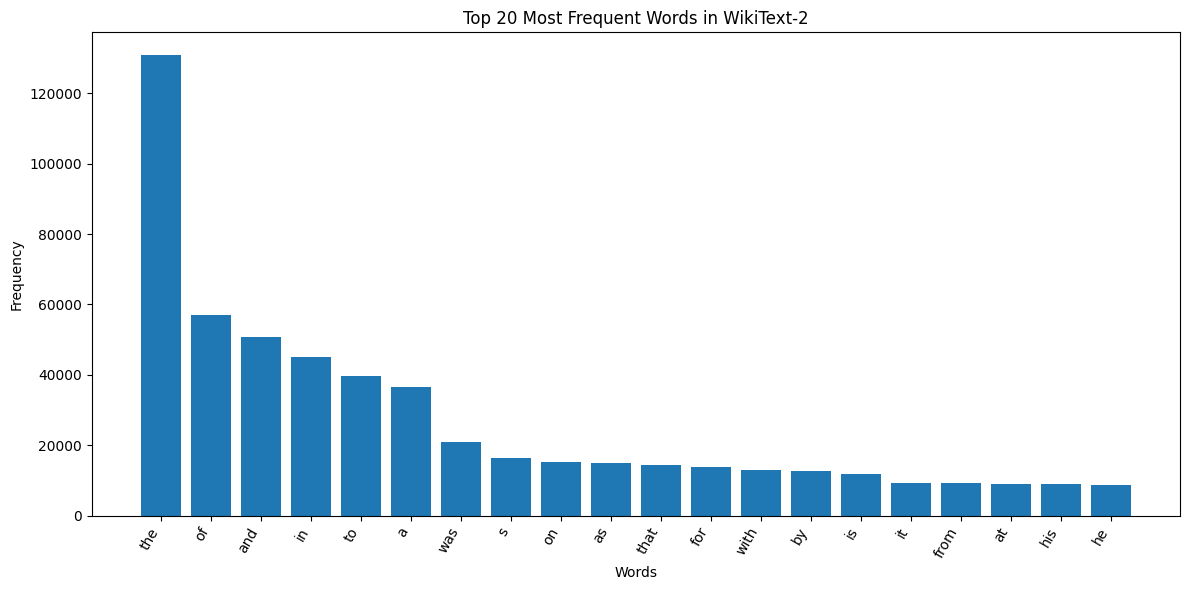

In [9]:
# --------------------------------------------------
# STEP 8: PLOT THE TOP 20 WORDS
# --------------------------------------------------

words = [item[0] for item in top_20]
frequencies = [item[1] for item in top_20]

plt.figure(figsize=(12, 6))

plt.bar(words, frequencies)

plt.title("Top 20 Most Frequent Words in WikiText-2")
plt.xlabel("Words")
plt.ylabel("Frequency")

plt.xticks(rotation=60, ha="right")
plt.tight_layout()
plt.show()

In [10]:
# --------------------------------------------------
# STEP 9: DISPLAY AN EXAMPLE PROBABILITY CALCULATION
# --------------------------------------------------

example_word = selected_words[0]
example_frequency = word_frequency.get(example_word, 0)

print("\nEXAMPLE CALCULATION")
print(f"Word: {example_word}")
print(f"Frequency: {example_frequency}")
print(f"Total tokens: {total_tokens}")
print(
    f"Unigram probability = "
    f"{example_frequency} / {total_tokens} = "
    f"{example_frequency / total_tokens:.8f}"
)


EXAMPLE CALCULATION
Word: the
Frequency: 130771
Total tokens: 1757552
Unigram probability = 130771 / 1757552 = 0.07440520
